# Module 5 — Model Development: clustering, validation and personas
ML Engineer (modelling + evaluation) roles. Lecture 9 workflow: *feature selection → proximity measure →
clustering criterion → algorithms → validation → interpretation*.

1. Clustering tendency (Hopkins statistic) — is there structure worth clustering?
2. **K-Means**: elbow (SSE), silhouette, Davies–Bouldin, Calinski–Harabasz, cross-validated SSE, bootstrap stability
3. **Hierarchical (AGNES)**: single / complete / average / Ward linkage, dendrogram, cophenetic correlation
4. **DBSCAN**: k-distance graph for Eps, MinPts grid, noise analysis
5. Algorithm comparison and choice
6. Validation of the final model: temporal hold-out (2014J), external measures vs final result, OULAD-only robustness
7. Profiles, persona names and an explainable **decision-tree surrogate** (Lecture 10)

In [1]:
import sys, json
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src")) if (Path.cwd().parent / "src").exists() else sys.path.insert(0, "src")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, joblib
from scipy.cluster.hierarchy import dendrogram
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import adjusted_rand_score, silhouette_samples, confusion_matrix, classification_report
from sklearn.neighbors import NearestNeighbors
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree
from sklearn.model_selection import train_test_split
from edtech import config as C, features as F, modeling as M, business as B, utils as U, viz as V
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 200); pd.set_option("display.max_colwidth", 80)

feat = pd.read_parquet(C.PROCESSED / "learner_features.parquet")
pipe = joblib.load(C.MODELS / "feature_pipeline.joblib")
SEL = pipe.features
ZC = [f"z_{c}" for c in SEL]
train = feat[(feat.split == "train") & (feat.population == "clustered")].reset_index(drop=True)
mon = feat[(feat.split == "monitor") & (feat.population == "clustered")].reset_index(drop=True)
X, Xm = train[ZC].to_numpy(), mon[ZC].to_numpy()
print("train:", X.shape, " hold-out 2014J:", Xm.shape)

train: (18670, 10)  hold-out 2014J: (9830, 10)


## 1. Clustering tendency — Hopkins statistic
H ≈ 0.5 for uniformly random data, H → 1 for clustered data.

In [2]:
def hopkins(Z, m=1000, seed=C.SEED):
    rng = np.random.default_rng(seed)
    nn = NearestNeighbors(n_neighbors=2).fit(Z)
    idx = rng.choice(len(Z), m, replace=False)
    w = nn.kneighbors(Z[idx])[0][:, 1]
    U_ = rng.uniform(Z.min(0), Z.max(0), size=(m, Z.shape[1]))
    u = nn.kneighbors(U_, n_neighbors=1)[0][:, 0]
    return float(u.sum() / (u.sum() + w.sum()))
H = np.mean([hopkins(X, seed=s) for s in range(5)])
print(f"Hopkins statistic: {H:.3f}")

Hopkins statistic: 0.762


## 2. K-Means
Empirical rule of thumb (Lecture 9): k ≈ √(n/2) = √(16,500/2) ≈ 90 — far too many to act on; it only confirms that
k must be chosen with data-driven criteria and business usefulness.

In [3]:
scan = M.kmeans_scan(X, ks=range(2, 11))
cv = M.cv_sse(X, ks=range(2, 11), folds=5)
stab = pd.DataFrame([M.bootstrap_stability(X, k, n_boot=15) for k in range(2, 11)])
seed_ari = pd.DataFrame({"k": range(2, 11), "seed_ari": [M.seed_stability(X, k) for k in range(2, 11)]})
kt = scan.merge(cv, on="k").merge(stab, on="k").merge(seed_ari, on="k")
U.save_table(kt.round(4), "m5_kmeans_k_selection"); kt.round(3)

,k,sse,silhouette,davies_bouldin,calinski_harabasz,min_cluster_share,elbow_distance,heldout_mse_mean,heldout_mse_std,ari_mean,ari_min,ari_std,seed_ari
0,2,142144.602,0.242,1.693,5851.521,0.374,0.000,7.616,0.038,0.984,0.924,0.017,0.989
1,3,119836.018,0.206,1.679,5207.759,0.242,0.169,6.421,0.031,0.956,0.900,0.034,0.983
2,4,109591.049,0.170,1.841,4377.870,0.193,0.199,5.876,0.043,0.920,0.697,0.071,0.721
3,5,102212.717,0.183,1.713,3857.047,0.101,0.195,5.488,0.045,0.804,0.603,0.172,0.758
4,6,95295.133,0.174,1.734,3580.415,0.089,0.187,5.110,0.041,0.942,0.686,0.069,0.644
5,7,90875.746,0.160,1.727,3279.886,0.083,0.149,4.876,0.035,0.900,0.729,0.085,0.778
6,8,87211.538,0.160,1.778,3041.310,0.067,0.103,4.686,0.029,0.760,0.514,0.115,0.836
7,9,83860.691,0.154,1.812,2860.532,0.066,0.054,4.522,0.028,0.593,0.479,0.113,0.702
8,10,80835.813,0.145,1.837,2715.288,0.063,0.000,4.345,0.032,0.821,0.631,0.112,0.753


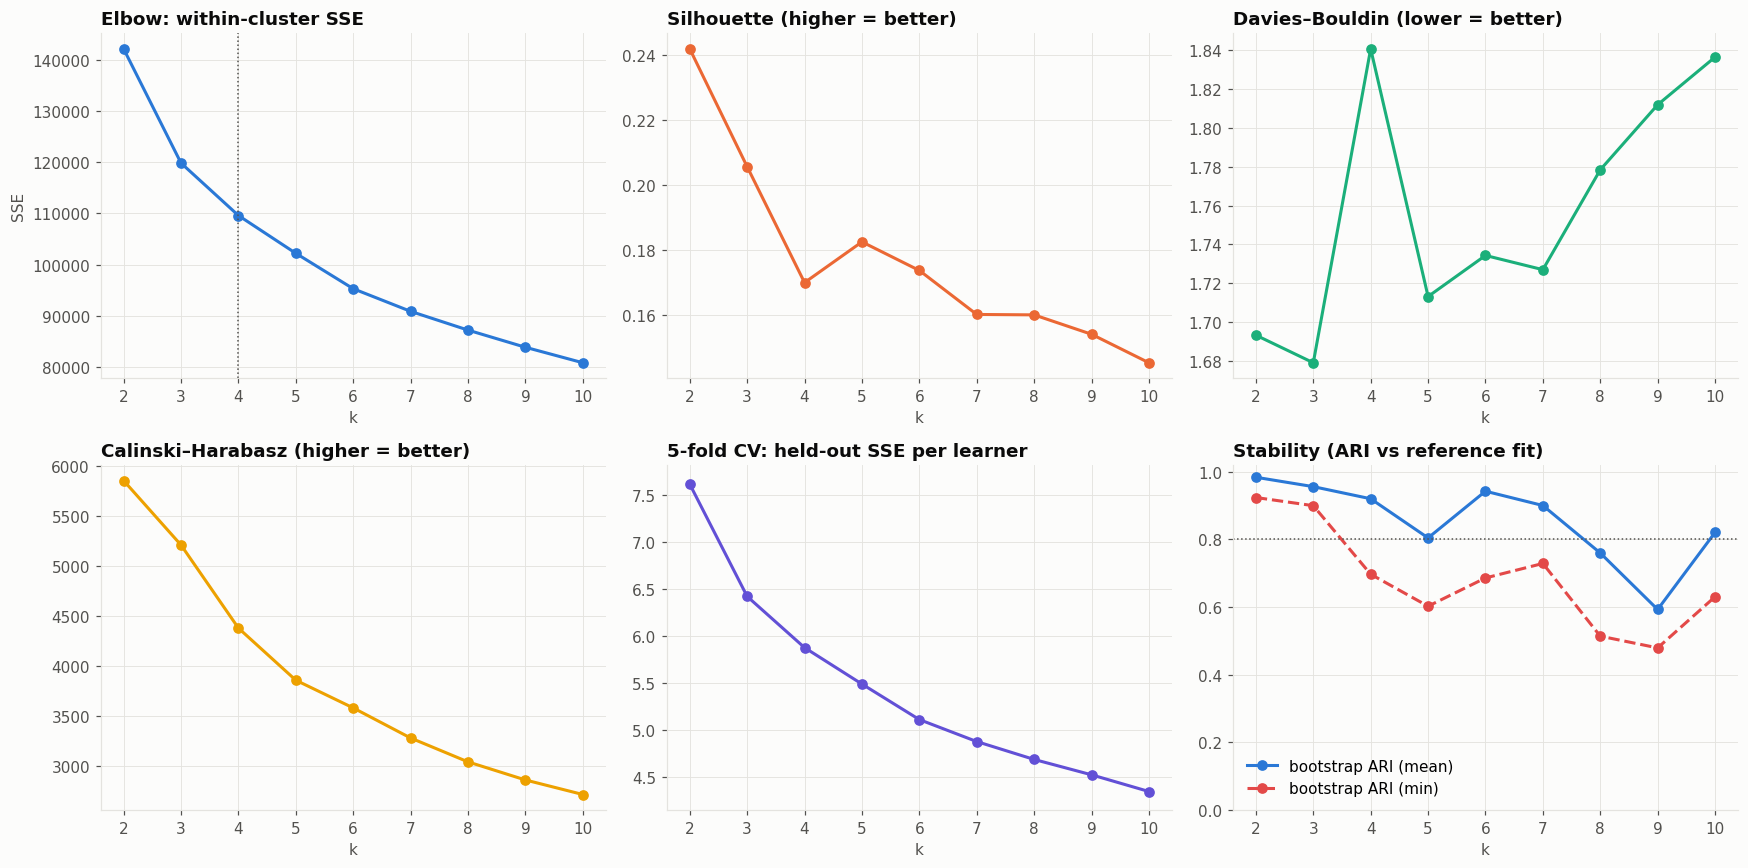

In [4]:
fig, ax = plt.subplots(2, 3, figsize=(16, 8))
ax[0, 0].plot(kt.k, kt.sse, marker="o"); ax[0, 0].set(title="Elbow: within-cluster SSE", xlabel="k", ylabel="SSE")
kel = int(kt.loc[kt.elbow_distance.idxmax(), "k"]); ax[0, 0].axvline(kel, color=V.TEXT2, ls=":", lw=1)
ax[0, 1].plot(kt.k, kt.silhouette, marker="o", color=V.CATEGORICAL[1]); ax[0, 1].set(title="Silhouette (higher = better)", xlabel="k")
ax[0, 2].plot(kt.k, kt.davies_bouldin, marker="o", color=V.CATEGORICAL[2]); ax[0, 2].set(title="Davies–Bouldin (lower = better)", xlabel="k")
ax[1, 0].plot(kt.k, kt.calinski_harabasz, marker="o", color=V.CATEGORICAL[3]); ax[1, 0].set(title="Calinski–Harabasz (higher = better)", xlabel="k")
ax[1, 1].errorbar(kt.k, kt.heldout_mse_mean, yerr=kt.heldout_mse_std, marker="o", color=V.CATEGORICAL[6]); ax[1, 1].set(title="5-fold CV: held-out SSE per learner", xlabel="k")
ax[1, 2].plot(kt.k, kt.ari_mean, marker="o", color=V.CATEGORICAL[0], label="bootstrap ARI (mean)")
ax[1, 2].plot(kt.k, kt.ari_min, marker="o", color=V.CATEGORICAL[7], ls="--", label="bootstrap ARI (min)")
ax[1, 2].axhline(0.8, color=V.TEXT2, ls=":", lw=1); ax[1, 2].set(title="Stability (ARI vs reference fit)", xlabel="k", ylim=(0, 1.02)); ax[1, 2].legend()
fig.tight_layout(); V.save(fig, "m5_k_selection"); plt.show()

### Selection rule (decided before looking at personas)
1. **Admissible** k: every cluster ≥ 5% of learners (actionable size) and bootstrap ARI_min ≥ 0.80 (stable).
2. Among admissible k, rank silhouette (↑), Davies–Bouldin (↓) and Calinski–Harabasz (↑); the best mean rank wins.
3. Sanity check against the elbow and the cross-validated SSE curve.

In [5]:
adm = kt[(kt.min_cluster_share >= 0.05) & (kt.ari_min >= 0.80) & (kt.k >= 3)].copy()
adm["rank_sil"] = adm.silhouette.rank(ascending=False)
adm["rank_db"] = adm.davies_bouldin.rank(ascending=True)
adm["rank_ch"] = adm.calinski_harabasz.rank(ascending=False)
adm["mean_rank"] = adm[["rank_sil", "rank_db", "rank_ch"]].mean(1)
K = int(adm.sort_values(["mean_rank", "silhouette"], ascending=[True, False]).iloc[0].k)
print("elbow k:", kel, "| selected k:", K)
adm[["k", "silhouette", "davies_bouldin", "calinski_harabasz", "min_cluster_share", "ari_min", "mean_rank"]].round(3)

elbow k: 4 | selected k: 3


,k,silhouette,davies_bouldin,calinski_harabasz,min_cluster_share,ari_min,mean_rank
1,3,0.206,1.679,5207.759,0.242,0.9,1.0


**Result: k = 3 behavioural clusters** (plus the rule-based Non-starter segment = 4 segments in total).
* k = 2 has the highest silhouette but only separates "engaged" from "disengaged" — it cannot distinguish *how*
  engaged learners study, which is the point of the business question (excluded by design: k ≥ 3).
* The elbow (maximum distance to the SSE chord) is at k = 4, but from k = 4 upwards the **bootstrap ARI minimum
  drops below 0.80** (0.70 at k = 4) and different random starts give different partitions (seed ARI 0.72): extra
  clusters are carved out of a continuum and are not reproducible. Personas built on them would change every time
  the model is retrained.
* k = 3 wins all three internal criteria among the admissible values, is stable (bootstrap ARI 0.96, min 0.90), and
  has no cluster below 24% of learners.

Silhouette values around 0.2 are typical for behavioural data, where learners vary continuously; the Hopkins
statistic (≈ 0.76) confirms there *is* structure, but it is gradient-like rather than made of well-separated blobs.
This is why stability, not silhouette alone, drives the choice.

## 3. Hierarchical clustering (AGNES)
Agglomerative clustering needs the full distance matrix (O(n²) memory), so it is run on a stratified random
sample of 6,000 training learners — a scalability limit that matters for deployment.

In [6]:
hc, hz = M.hierarchical_compare(X, K, sample=6000)
U.save_table(hc.round(4), "m5_hierarchical_linkages"); hc.round(3)

,linkage,cophenetic_corr,silhouette,davies_bouldin,calinski_harabasz,largest_cluster_share,smallest_cluster_share
0,single,0.312,0.214,0.561,3.465,1.000,0.000
1,complete,0.483,0.104,2.295,827.183,0.418,0.198
2,average,0.605,0.158,1.306,152.414,0.968,0.000
3,ward,0.515,0.150,2.019,1293.673,0.390,0.270


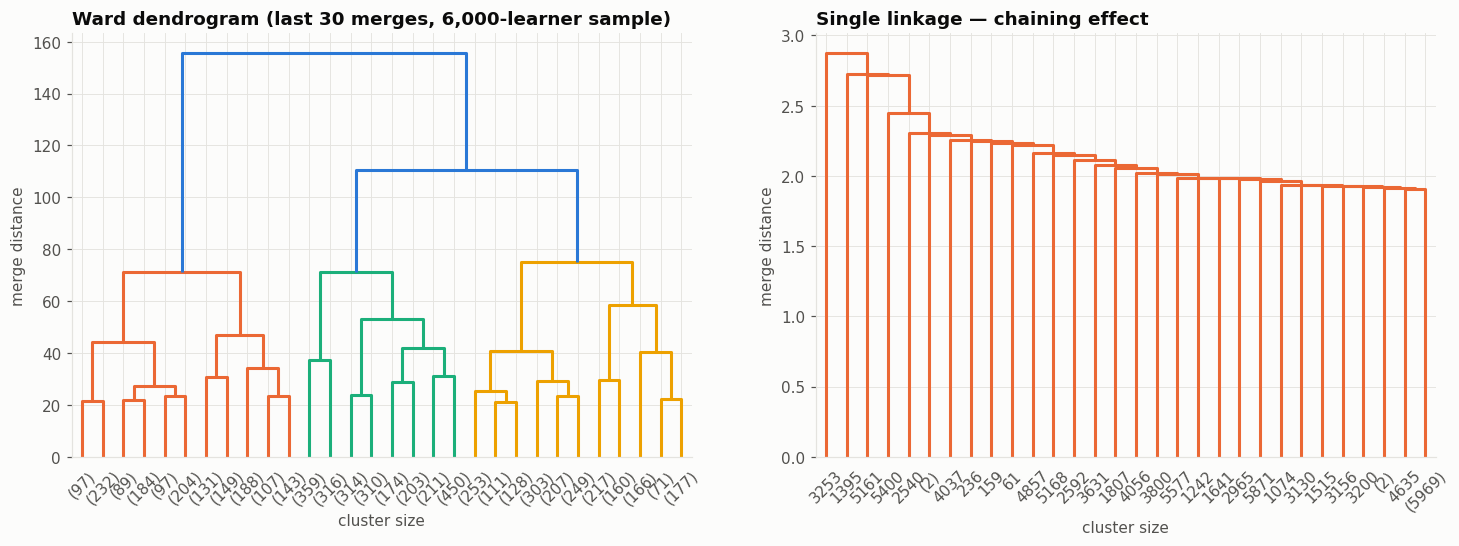

ARI Ward vs K-Means on the sample: 0.443


In [7]:
fig, ax = plt.subplots(1, 2, figsize=(16, 5))
dendrogram(hz["Z"]["ward"], truncate_mode="lastp", p=30, ax=ax[0], color_threshold=None, above_threshold_color=V.CATEGORICAL[0])
ax[0].set(title="Ward dendrogram (last 30 merges, 6,000-learner sample)", xlabel="cluster size", ylabel="merge distance")
dendrogram(hz["Z"]["single"], truncate_mode="lastp", p=30, ax=ax[1], color_threshold=None, above_threshold_color=V.CATEGORICAL[1])
ax[1].set(title="Single linkage — chaining effect", xlabel="cluster size", ylabel="merge distance")
V.save(fig, "m5_dendrograms"); plt.show()
Xs = X[hz["idx"]]
ward_lab = AgglomerativeClustering(n_clusters=K, linkage="ward").fit_predict(Xs)
km_tmp = KMeans(K, n_init=10, random_state=C.SEED).fit(X)
ari_ward_km = adjusted_rand_score(ward_lab, km_tmp.predict(Xs)); print(f"ARI Ward vs K-Means on the sample: {ari_ward_km:.3f}")

Single and average linkage put almost every learner into one cluster and leave tiny clusters of extreme points
(chaining: largest cluster 99.97% and 96.8% of the sample) — useless for segmentation. Complete linkage and **Ward**
(which minimises the same within-cluster variance as K-Means) give balanced clusters; Ward has the higher
Calinski–Harabasz. Ward and K-Means agree only moderately (ARI ≈ 0.44): both separate disengaged from engaged
learners, but in a behavioural continuum the boundary between "achievers" and "crammers" moves with the algorithm's
criterion. The lower cophenetic correlations (0.3–0.6) also show the dendrogram distorts the original distances.

## 4. DBSCAN
MinPts = 2 × dimensions = 20 (common heuristic). Eps is read from the "knee" of the sorted 20-NN distance curve.

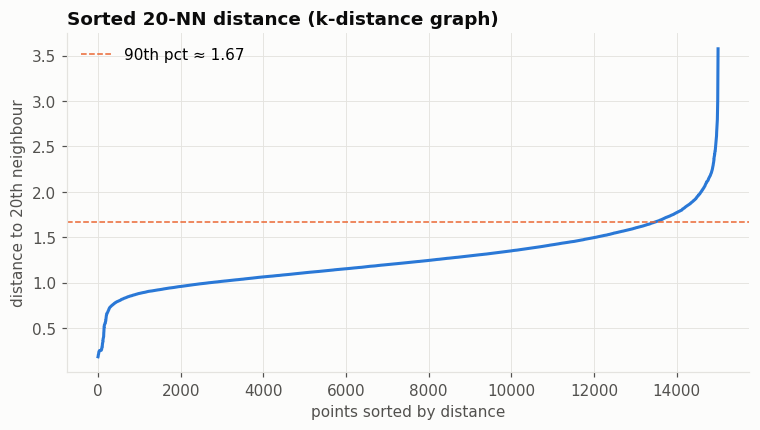

,min_pts,eps,n_clusters,noise_share,largest_cluster_share,silhouette,davies_bouldin,calinski_harabasz
0,10,0.8,24,0.797,0.118,-0.135,1.168,230.393
1,10,1.0,13,0.412,0.488,-0.189,1.378,109.844
2,10,1.2,4,0.147,0.838,0.048,1.188,164.281
3,10,1.4,1,0.044,0.956,NaN,NaN,NaN
4,10,1.6,1,0.013,0.987,NaN,NaN,NaN
5,10,1.8,1,0.004,0.996,NaN,NaN,NaN
6,10,2.0,1,0.001,0.999,NaN,NaN,NaN
7,10,2.2,1,0.001,0.999,NaN,NaN,NaN
8,10,2.4,1,0.000,1.000,NaN,NaN,NaN
9,20,0.8,7,0.913,0.040,0.297,0.792,859.770


In [8]:
kd = M.k_distance(X, 20)
knee = float(np.quantile(kd, 0.90))
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(kd); ax.axhline(knee, color=V.CATEGORICAL[1], ls="--", lw=1, label=f"90th pct ≈ {knee:.2f}")
ax.set(title="Sorted 20-NN distance (k-distance graph)", xlabel="points sorted by distance", ylabel="distance to 20th neighbour"); ax.legend()
V.save(fig, "m5_kdistance"); plt.show()
eps_grid = np.round(np.linspace(0.8, 2.4, 9), 2)
db = M.dbscan_grid(X, eps_grid, [10, 20, 40], sample=15000)
U.save_table(db.round(4), "m5_dbscan_grid"); db.round(3)

In [9]:
# representative setting: at least 2 clusters with at most 10% noise, best silhouette among those
best_db = db[(db.n_clusters >= 2) & (db.noise_share <= 0.10)].sort_values("silhouette", ascending=False).head(1)
eps_b, mp_b = (float(best_db.eps.iloc[0]), int(best_db.min_pts.iloc[0])) if len(best_db) else (knee, 20)
idx15 = np.sort(np.random.default_rng(C.SEED).choice(len(X), 15000, replace=False))
db_lab = DBSCAN(eps=eps_b, min_samples=mp_b).fit_predict(X[idx15])
noise = train.iloc[idx15][db_lab == -1]; core = train.iloc[idx15][db_lab != -1]
noise_cmp = pd.DataFrame({"DBSCAN noise": noise[SEL + ["is_pass"]].median(), "DBSCAN clustered": core[SEL + ["is_pass"]].median()}).round(3)
print(f"best DBSCAN: eps={eps_b}, MinPts={mp_b}, clusters={len(set(db_lab)) - (1 if -1 in db_lab else 0)}, noise={np.mean(db_lab == -1):.1%}")
noise_cmp

best DBSCAN: eps=1.4, MinPts=20, clusters=2, noise=8.0%


,DBSCAN noise,DBSCAN clustered
recency_fraction,0.366,0.085
active_day_fraction,0.099,0.193
clicks_per_active_day,19.808,16.000
weekly_cv_active_span,1.596,1.169
deadline_click_ratio,2.629,1.853
avg_score_scheduled,22.000,64.000
last_minute_submission_share,0.400,0.000
video_completion_rate,0.569,0.644
forum_posts_per_week,0.029,0.051
night_login_share,0.298,0.158


Learner behaviour forms one dense continuum with sparser edges rather than separated dense islands. DBSCAN therefore
returns either one giant cluster plus noise (small Eps → many "noise" learners) or merges everything (large Eps).
The settings that produce ≥ 2 clusters create one dominant cluster and tiny fragments. DBSCAN is still useful as a
**multivariate outlier detector** (Lecture 7: outliers = points far from any cluster): its noise points are the
extreme forum posters, very bursty and very late learners, which the K-Means `is_atypical` flag also captures.

## 5. Algorithm comparison

In [10]:
km = KMeans(K, n_init=20, random_state=C.SEED).fit(X)
lab = km.labels_
comp_rows = [{"algorithm": f"K-Means (k={K})", "clusters": K, "noise_share": 0.0, **M.internal_scores(X, lab),
              "largest_cluster_share": np.bincount(lab).max() / len(lab),
              "stability_ari": float(kt.loc[kt.k == K, "ari_mean"].iloc[0]),
              "scales_to_all_learners": "yes, O(nkt)", "assigns_new_learners": "yes (nearest centroid)"}]
hw = hc.set_index("linkage").loc["ward"]
comp_rows.append({"algorithm": f"Agglomerative Ward (k={K}, 6k sample)", "clusters": K, "noise_share": 0.0,
                  "silhouette": hw.silhouette, "davies_bouldin": hw.davies_bouldin, "calinski_harabasz": hw.calinski_harabasz,
                  "largest_cluster_share": hw.largest_cluster_share, "stability_ari": ari_ward_km,
                  "scales_to_all_learners": "no, O(n²) memory", "assigns_new_learners": "no (needs re-fit or a classifier)"})
dbs = M.internal_scores(X[idx15], db_lab)
comp_rows.append({"algorithm": f"DBSCAN (eps={eps_b}, MinPts={mp_b})", "clusters": len(set(db_lab) - {-1}), "noise_share": float(np.mean(db_lab == -1)),
                  **dbs, "largest_cluster_share": float(np.bincount(db_lab[db_lab >= 0]).max() / len(db_lab)), "stability_ari": np.nan,
                  "scales_to_all_learners": "yes", "assigns_new_learners": "partly (core-point neighbourhood)"})
algo = pd.DataFrame(comp_rows); U.save_table(algo.round(4), "m5_algorithm_comparison"); algo.round(3)

,algorithm,clusters,noise_share,silhouette,davies_bouldin,calinski_harabasz,largest_cluster_share,stability_ari,scales_to_all_learners,assigns_new_learners
0,K-Means (k=3),3,0.00,0.206,1.679,5207.759,0.384,0.956,"yes, O(nkt)",yes (nearest centroid)
1,"Agglomerative Ward (k=3, 6k sample)",3,0.00,0.150,2.019,1293.673,0.390,0.443,"no, O(n²) memory",no (needs re-fit or a classifier)
2,"DBSCAN (eps=1.4, MinPts=20)",2,0.08,0.253,0.956,184.427,0.915,NaN,yes,partly (core-point neighbourhood)


**Choice: K-Means.** It has the best balance of separation (silhouette / DB / CH), stability and actionable
cluster sizes, scales to every learner, and assigns a new learner in microseconds (nearest centroid) — a
requirement for the API. Ward agrees with it; DBSCAN confirms there is no density-separated structure and is kept
as an outlier lens. K-Means' known weaknesses (Lecture 9: sensitivity to outliers, convex clusters) are mitigated by
Yeo-Johnson + winsorisation and by the stability checks.

## 6. Validation of the final model
### 6a. Silhouette per cluster

In [11]:
idx = np.random.default_rng(C.SEED).choice(len(X), 8000, replace=False)
s_val = silhouette_samples(X[idx], lab[idx])
sil_c = pd.DataFrame({"cluster": lab[idx], "silhouette": s_val}).groupby("cluster").silhouette.agg(["mean", "median", lambda x: (x < 0).mean()])
sil_c.columns = ["mean_silhouette", "median_silhouette", "share_negative"]; sil_c.round(3)

,mean_silhouette,median_silhouette,share_negative
cluster,,,
0,0.214,0.223,0.019
1,0.282,0.292,0.000
2,0.122,0.122,0.114


### 6b. Temporal hold-out: does the 2013B–2014B segmentation hold for the unseen 2014J cohort?
(Lecture 9 cross-validation idea applied over time.) We (i) score 2014J with the frozen model and (ii) refit K-Means
on 2014J alone; high ARI between the two assignments means the segment structure is stable over time.

In [12]:
lab_m_frozen = km.predict(Xm)
km_m = KMeans(K, n_init=20, random_state=C.SEED).fit(Xm)
temporal = {"silhouette_train": M.internal_scores(X, lab)["silhouette"],
            "silhouette_2014J_frozen": M.internal_scores(Xm, lab_m_frozen)["silhouette"],
            "ari_frozen_vs_refit_2014J": float(adjusted_rand_score(lab_m_frozen, km_m.labels_)),
            "train_shares": (np.bincount(lab) / len(lab)).round(4).tolist(),
            "holdout_shares": (np.bincount(lab_m_frozen, minlength=K) / len(lab_m_frozen)).round(4).tolist()}
temporal

{'silhouette_train': 0.20566131370253202,
 'silhouette_2014J_frozen': 0.19290928993517542,
 'ari_frozen_vs_refit_2014J': 0.8388972124183088,
 'train_shares': [0.2418, 0.3841, 0.374],
 'holdout_shares': [0.2335, 0.3353, 0.4312]}

### 6c. Robustness: does the segmentation depend on the synthetic fields?
Re-cluster using only the six OULAD features and compare with the full model (ARI). Moderate-to-high agreement
means the synthetic fields *refine* the real structure rather than create it.

In [13]:
oulad_only = ["z_recency_fraction", "z_active_day_fraction", "z_clicks_per_active_day", "z_weekly_cv_active_span",
              "z_deadline_click_ratio", "z_avg_score_scheduled"]
lab_o = KMeans(K, n_init=20, random_state=C.SEED).fit_predict(train[oulad_only].to_numpy())
robust = {"ari_full_vs_oulad_only": float(adjusted_rand_score(lab, lab_o))}
pd.crosstab(lab, lab_o, rownames=["full model"], colnames=["OULAD-only model"])

OULAD-only model,0,1,2
full model,,,
0,16,131,4368
1,6489,603,80
2,715,5779,489


## 7. Profiles and persona names
Centroids are inverted back to original units. Persona names come from a reproducible matching of each centroid
to behavioural archetypes (`business.name_clusters`, Hungarian assignment) rather than being hand-picked.

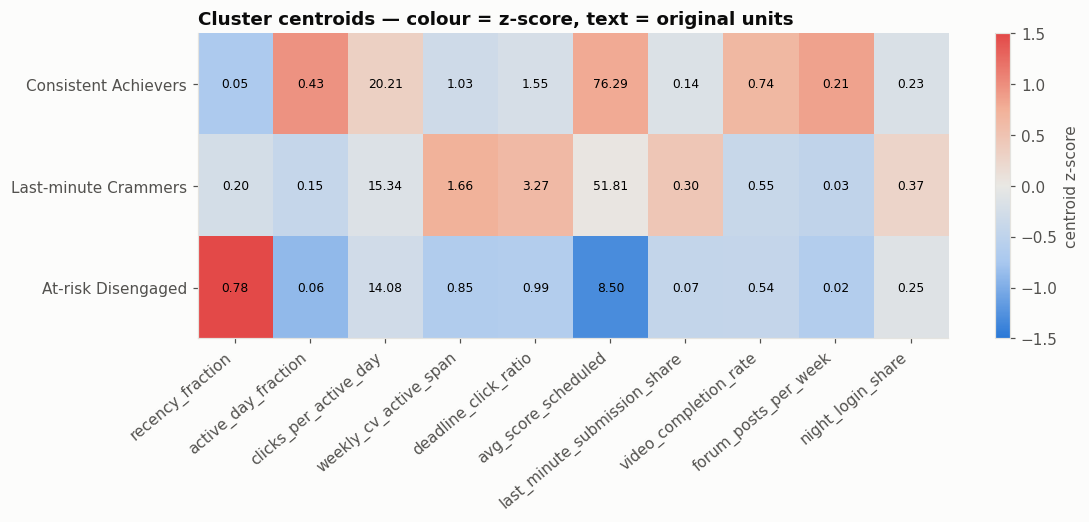

,recency_fraction,active_day_fraction,clicks_per_active_day,weekly_cv_active_span,deadline_click_ratio,avg_score_scheduled,last_minute_submission_share,video_completion_rate,forum_posts_per_week,night_login_share
Consistent Achievers,0.05,0.43,20.21,1.03,1.55,76.29,0.14,0.74,0.21,0.23
Last-minute Crammers,0.20,0.15,15.34,1.66,3.27,51.81,0.30,0.55,0.03,0.37
At-risk Disengaged,0.78,0.06,14.08,0.85,0.99,8.50,0.07,0.54,0.02,0.25


In [14]:
zcent = pd.DataFrame(km.cluster_centers_, columns=SEL)
names = B.name_clusters(zcent)
order = ["Consistent Achievers", "Steady Independent Learners", "Last-minute Crammers", "Night-owl Learners",
         "Struggling Strivers", "Fading Starters", "At-risk Disengaged"]
ranked = sorted(names.items(), key=lambda kv: order.index(kv[1]))
persona_by_cluster = {-1: {**B.NON_STARTER}}
for i, (c, n) in enumerate(ranked, start=1):
    persona_by_cluster[c] = {"segment_id": f"S{i}", "name": n}
cent = pipe.inverse_centroids(km.cluster_centers_)
cent.index = [persona_by_cluster[c]["name"] for c in range(K)]
cent = cent.loc[[persona_by_cluster[c]["name"] for c, _ in ranked]]
U.save_table(cent.round(3).reset_index(names="persona"), "m5_centroids_original_units")
zc = zcent.copy(); zc.index = [persona_by_cluster[c]["name"] for c in range(K)]; zc = zc.loc[cent.index]
fig, ax = plt.subplots(figsize=(11, 0.7 * K + 1.5))
im = ax.imshow(zc.to_numpy(), cmap=V.DIVERGING, vmin=-1.5, vmax=1.5, aspect="auto")
ax.set_xticks(range(len(SEL)), SEL, rotation=40, ha="right"); ax.set_yticks(range(K), zc.index)
for i in range(K):
    for j in range(len(SEL)):
        ax.text(j, i, f"{cent.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
ax.grid(False); fig.colorbar(im, label="centroid z-score"); ax.set_title("Cluster centroids — colour = z-score, text = original units")
V.save(fig, "m5_centroid_heatmap"); plt.show()
cent.round(2)

In [15]:
# Final serving bundle; distance p95 per cluster on training data defines 'atypical' learners for monitoring
d_train = km.transform(X).min(1)
p95 = {int(c): float(np.quantile(d_train[lab == c], 0.95)) for c in range(K)}
model = M.SegmentationModel(pipeline=pipe, kmeans=km, persona_by_cluster=persona_by_cluster, distance_p95=p95)
seg_all = model.assign(feat)
feat_seg = pd.concat([feat.reset_index(drop=True), seg_all.reset_index(drop=True)], axis=1)
model.reference_shares = feat_seg[feat_seg.split == "train"].segment_id.value_counts(normalize=True).round(4).to_dict()
joblib.dump(model, C.MODELS / "segmentation_model.joblib")
feat_seg.to_parquet(C.PROCESSED / "learner_segments.parquet", index=False)
sizes = feat_seg.groupby(["segment_id", "persona"]).size().rename("enrollments").reset_index()
sizes["share"] = (sizes.enrollments / len(feat_seg)).round(4)
U.save_table(sizes, "m5_segment_sizes"); sizes

,segment_id,persona,enrollments,share
0,S0,Non-starters,4093,0.1256
1,S1,Consistent Achievers,10468,0.3212
2,S2,Last-minute Crammers,11222,0.3443
3,S3,At-risk Disengaged,6810,0.2089


### 6d. External validation against the real outcome (never used in training)
Lecture 9 external measures: purity, NMI, ARI vs `final_result`. A behavioural segmentation is *not* supposed to
reproduce outcomes, but segments that separate outcome rates are more useful for targeting support.

In [16]:
ext = M.external_scores(feat_seg.segment_id.to_numpy(), feat_seg.final_result.to_numpy())
outc = pd.crosstab(feat_seg.persona, feat_seg.final_result, normalize="index").round(3)[["Distinction", "Pass", "Fail", "Withdrawn"]]
outc["at_risk_rate"] = outc.Fail + outc.Withdrawn
U.save_table(outc.reset_index(), "m5_outcome_by_segment"); print(ext); outc.sort_values("at_risk_rate")

{'purity': 0.6254717270579573, 'nmi': 0.3097855811336523, 'ari': 0.22604187947006912}


final_result,Distinction,Pass,Fail,Withdrawn,at_risk_rate
persona,,,,,
Consistent Achievers,0.225,0.671,0.074,0.030,0.104
Last-minute Crammers,0.060,0.474,0.307,0.160,0.467
At-risk Disengaged,0.000,0.003,0.347,0.650,0.997
Non-starters,0.000,0.001,0.114,0.885,0.999


## 8. Explainability: decision-tree surrogate (Lecture 10)
A shallow classification tree learns to predict the K-Means segment from the *original-unit* features. Its rules
give tutors plain-language explanations ("if active on < 9% of days and score < 30 → At-risk Disengaged"), and its
test accuracy shows how rule-like the segments are.

In [17]:
y = train.index.map(lambda i: persona_by_cluster[int(lab[i])]["name"])
Xo = train[SEL].fillna(train[SEL].median())
Xtr, Xte, ytr, yte = train_test_split(Xo, y, test_size=0.3, random_state=C.SEED, stratify=y)
tree = DecisionTreeClassifier(max_depth=4, min_samples_leaf=100, random_state=C.SEED).fit(Xtr, ytr)
acc_te = tree.score(Xte, yte)
acc_2014J = tree.score(mon[SEL].fillna(train[SEL].median()), [persona_by_cluster[int(c)]["name"] for c in lab_m_frozen])
print(f"surrogate tree accuracy — test: {acc_te:.3f} | 2014J hold-out: {acc_2014J:.3f}")
rules = export_text(tree, feature_names=SEL, decimals=2)
(C.MODELS / "surrogate_tree_rules.txt").write_text(rules)
joblib.dump(tree, C.MODELS / "surrogate_tree.joblib")
cmx = pd.DataFrame(confusion_matrix(yte, tree.predict(Xte), labels=tree.classes_), index=tree.classes_, columns=tree.classes_)
U.save_table(cmx.reset_index(names="true"), "m5_surrogate_confusion"); cmx

surrogate tree accuracy — test: 0.870 | 2014J hold-out: 0.867


,At-risk Disengaged,Consistent Achievers,Last-minute Crammers
At-risk Disengaged,1180,22,152
Consistent Achievers,4,1888,260
Last-minute Crammers,98,193,1804


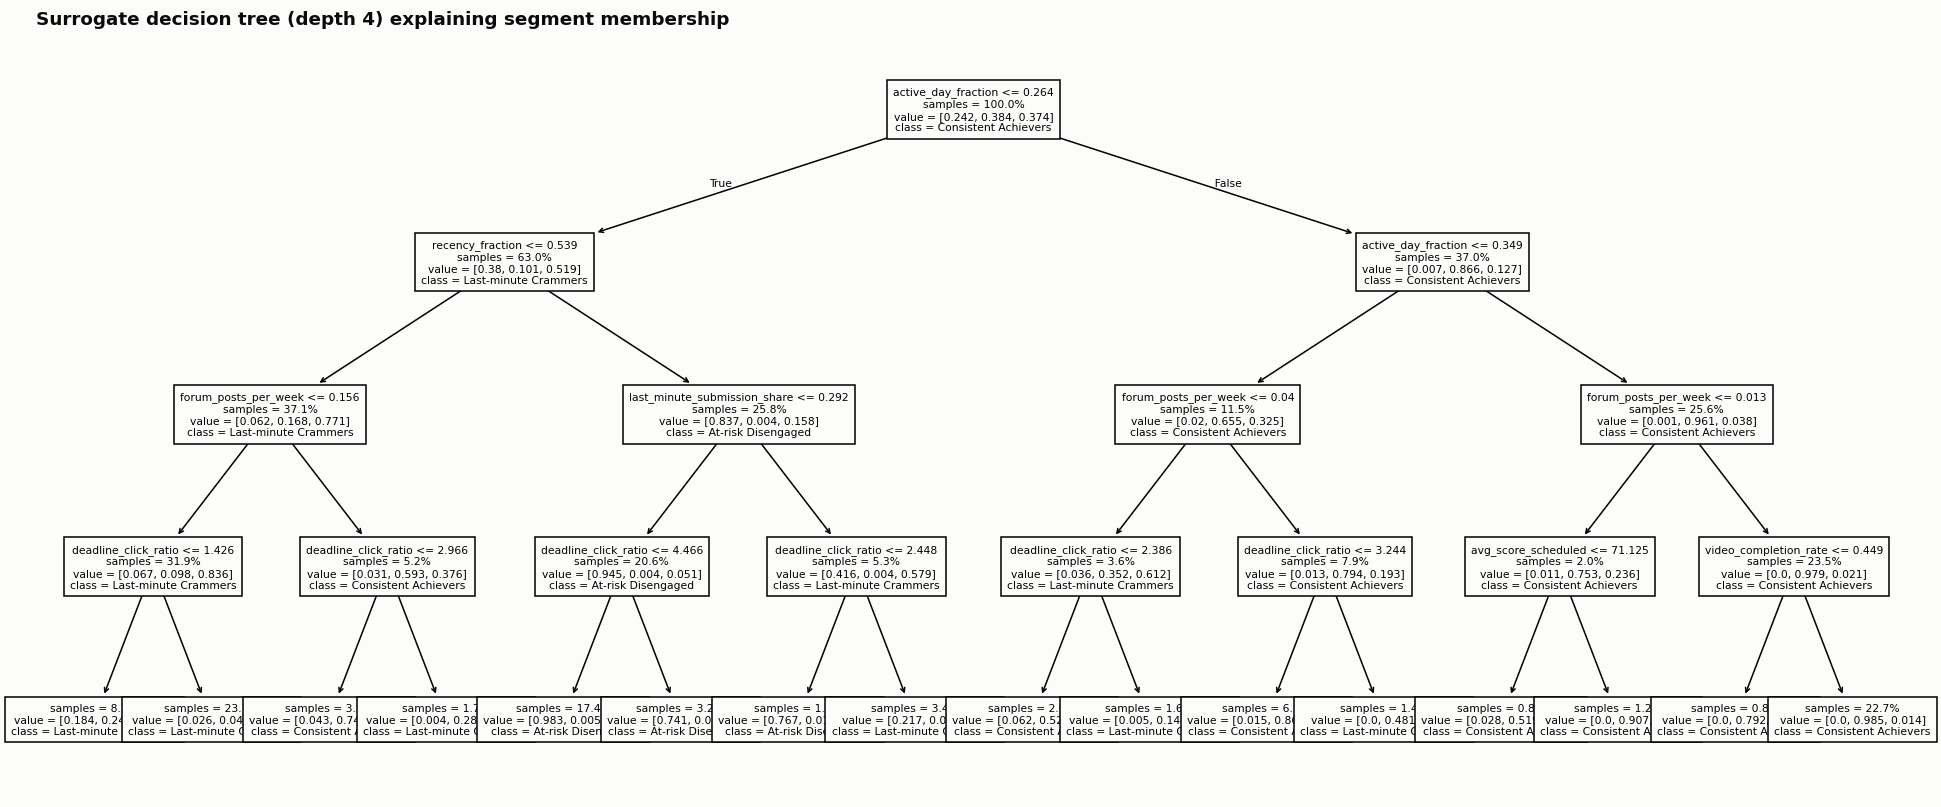

active_day_fraction             0.473
recency_fraction                0.330
deadline_click_ratio            0.074
forum_posts_per_week            0.068
last_minute_submission_share    0.051
avg_score_scheduled             0.003
video_completion_rate           0.001
weekly_cv_active_span           0.000
clicks_per_active_day           0.000
night_login_share               0.000
dtype: float64

In [18]:
fig, ax = plt.subplots(figsize=(22, 9))
plot_tree(tree, feature_names=SEL, class_names=list(tree.classes_), filled=False, impurity=False, proportion=True, fontsize=7, ax=ax)
ax.set_title("Surrogate decision tree (depth 4) explaining segment membership"); V.save(fig, "m5_surrogate_tree"); plt.show()
imp = pd.Series(tree.feature_importances_, index=SEL).sort_values(ascending=False).round(3); imp

In [19]:
fi = pd.DataFrame({"feature": SEL, "between_cluster_F_ratio": [
    np.var(km.cluster_centers_[:, j]) / np.mean([X[lab == c, j].var() for c in range(K)]) for j in range(len(SEL))]}
).sort_values("between_cluster_F_ratio", ascending=False).round(3)
U.save_table(fi, "m5_feature_separation"); fi

,feature,between_cluster_F_ratio
0,recency_fraction,3.545
5,avg_score_scheduled,2.377
1,active_day_fraction,1.773
8,forum_posts_per_week,0.864
3,weekly_cv_active_span,0.467
7,video_completion_rate,0.331
4,deadline_click_ratio,0.329
6,last_minute_submission_share,0.165
2,clicks_per_active_day,0.069
9,night_login_share,0.040


In [20]:
U.save_metrics("m5", {"hopkins": H, "k_selected": K, "k_elbow": kel, "k_table": kt.round(4).to_dict("records"),
                      "hierarchical": hc.round(4).to_dict("records"), "ari_ward_vs_kmeans": ari_ward_km,
                      "dbscan_best": {"eps": eps_b, "min_pts": mp_b, "noise_share": float(np.mean(db_lab == -1)),
                                      "n_clusters": len(set(db_lab) - {-1})},
                      "algorithm_comparison": algo.round(4).to_dict("records"), "temporal": temporal, "robustness": robust,
                      "external": ext, "surrogate_acc_test": acc_te, "surrogate_acc_2014J": acc_2014J,
                      "persona_by_cluster": {str(k): v for k, v in persona_by_cluster.items()},
                      "segment_sizes": sizes.to_dict("records"), "silhouette_by_cluster": sil_c.round(4).reset_index().to_dict("records"),
                      "tree_importance": imp.to_dict()})